In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange
from scipy.special import jv

### radial grid

In [34]:
dx = 0.01     
x = np.arange(0.01, 1.9, dx)

# Vector Potential

https://linkinghub.elsevier.com/retrieve/pii/S0375960118309587


$$
A_z(r) = m\omega_C F_0 J_2(\lambda r)\\
A_{\theta} = B_z
$$

in the unit of the code $m=1,\; e=1$. Thus $\omega_C = B_z$

In [35]:
Bz = 4

def A_z(r,Bz):
    F_0 = 1
    lambd =7.5
    result = Bz*F_0*jv(2, lambd*r)
    return result

# Magnetic field

$$
B_{\theta} = - \partial_r A_z\\
B_z = \frac{m\omega}{e}
$$

In [36]:
def B_th(r, Bz):
    F_0 = 1
    lambd =7.5
    return - Bz*F_0*0.5*(jv(1, lambd*r)-jv(3, lambd*r))*lambd

Text(0.5, 0.98, 'Magnetic configuration')

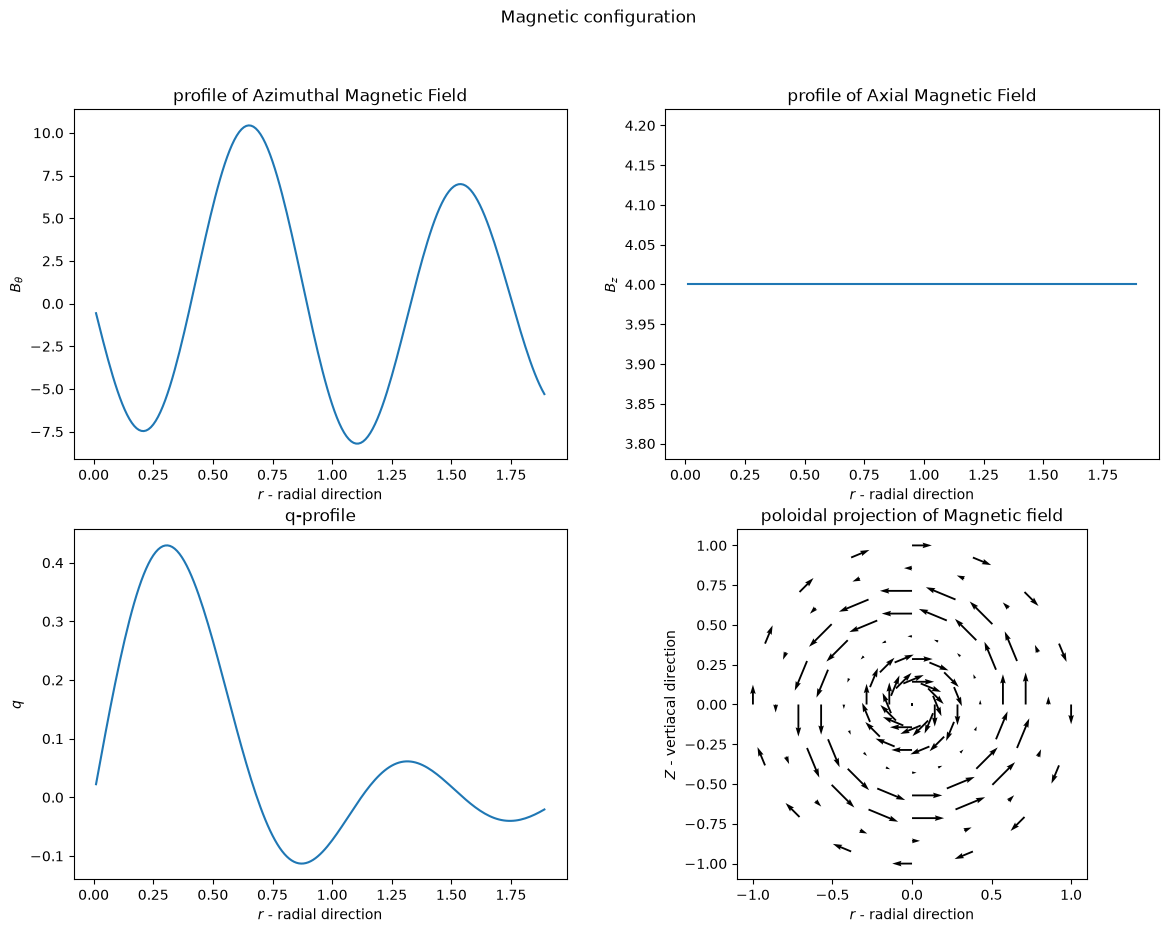

In [37]:
fig, ax = plt.subplots(2,2, figsize=(14,10))

ax[0,0].plot(x, B_th(x, Bz))
ax[0,0].set_xlabel('$r$ - radial direction')
ax[0,0].set_ylabel('$B_{\\theta}$')
ax[0,0].set_title('profile of Azimuthal Magnetic Field')


B_z = np.zeros(x.shape)
B_z = B_z + Bz
ax[0,1].plot(x, B_z)
ax[0,1].set_xlabel('$r$ - radial direction')
ax[0,1].set_ylabel('$B_z$')
ax[0,1].set_title('profile of Axial Magnetic Field')

# Toroidal flux
PhiT = Bz * np.pi*x**2
PhiTh = x * A_z(x, Bz)

q = PhiTh/PhiT
ax[1,0].plot(x, q)
ax[1,0].set_xlabel('$r$ - radial direction')
ax[1,0].set_ylabel('$q$')
ax[1,0].set_title('q-profile')

theta = np.linspace(0, 2*np.pi, 17)[:-1]
r = np.linspace(0,1,8)

R, TH = np.meshgrid(r,theta)

X = R*np.cos(TH)
Y = R*np.sin(TH)

Bth = B_th(R, Bz)
U = -np.sin(TH)*Bth
V =  np.cos(TH)*Bth

ax[1,1].quiver(X,Y,U,V)
ax[1,1].set_xlabel('$r$ - radial direction')
ax[1,1].set_ylabel('$Z$ - vertiacal direction')
ax[1,1].set_aspect('equal')
ax[1,1].set_title('poloidal projection of Magnetic field')
fig.suptitle('Magnetic configuration')

# The magnetic field lines ... to be continued ...

c:\Users\Utente\Projects\Marseille\.venv\Lib\site-packages\matplotlib\patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


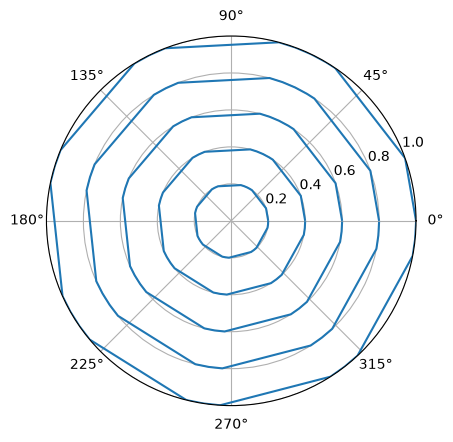

In [38]:
theta = np.linspace(0, 2*np.pi, 1000)[:-1]
r = np.linspace(0,1,100)

R, TH = np.meshgrid(theta,r)

X = R*np.cos(TH)
Y = R*np.sin(TH)

Bth = B_th(R, Bz)
U = -np.sin(TH)*Bth
V =  np.cos(TH)*Bth

ax = plt.subplot(polar=True)
ax.streamplot(theta, r, Bth, np.zeros(Bth.shape), arrowsize=0, density=.2 )


# superfici risonanti
- vengono indicate con il valore di $\iota$, ma in forma razionale ridotta ai minimi termini
- il valore ai minimi termini è determinato dai coefficienti dei numeri primi

COME SCEGLIERLE?
- Fisso un valore di $m\equiv \text{'giri toroidali'}$
- Vario il valore di $n\equiv \text{'giri poloidali}$
- Osservo che per le superfici risonanti $q(r_\text{ris}) = m/n$, la sezione di Poincarè poloidale, ha $m$ intersezioni, mentre quella toroidale, ne ha $n$.

Nota: i valori $m$,$n$ devono essere irriducibili

In [108]:
def mcd(m, n):
    return m if n == 0 else mcd(n, m % n)

In [124]:

m = np.arange(1,20)
n = m
M, N = np.meshgrid(m,n)
m = M.flatten()
n = N.flatten()

for i in np.arange(len(m))[::-1]:
    if mcd(m[i],n[i]) != 1:
        m = np.delete(m,i)
        n = np.delete(n,i)

q_rat = m/n

# solo sotto il primo massimo
xtmp = x[x<.35]
qtmp = q[x<.35]

m = m[q_rat<=qtmp.max()]
n = n[q_rat<=qtmp.max()]
q_rat = q_rat[q_rat<=qtmp.max()]

x_rat = np.interp(q_rat, qtmp, xtmp)


## Plot of the intersection of magnetic field lines
- each line start at $\theta=0$, and $z=0$ per ogni superficie $r=0$
- the $q=\frac{\partial z}{\partial \theta} = m / n$a

the evolution:
- $\theta$ can span on the all values, but it is always view in $\mod{2\pi}$
- $z$ is periodic $2\pi$, and it follows $z  = q(r) \theta$

the visualization:
- the polodial section at every multiple of $z = 2\pi\, k$, the value of $\theta=2\pi\,k/q(r)$ is plotted
- the torodial section, is the same but for $z = q(r) 2\pi k$, and $\theta=2\pi k$

(-0.35, 0.35)

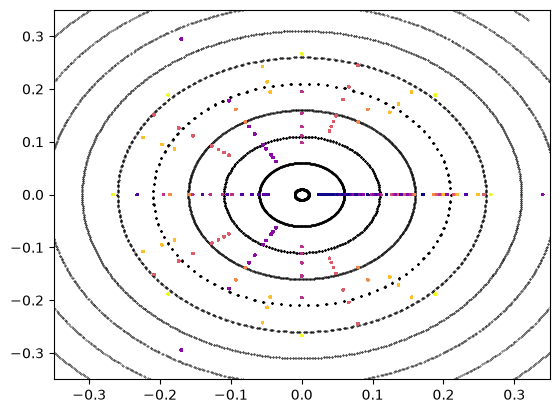

In [138]:
k=5
turns = 2*np.pi*np.arange(1000)

R, TURNS = np.meshgrid(x[::k], turns)

TH = TURNS / q[np.newaxis, ::k]
Z = TURNS * q[np.newaxis,::k]

plt.scatter(R*np.cos(TH), R*np.sin(TH), c='black', s=0.1)

R, TURNS = np.meshgrid(x_rat, turns)

TH = TURNS / q_rat[np.newaxis, :]
Z = TURNS * q_rat[np.newaxis,:]

m_grid = np.broadcast_to(m[np.newaxis, :], np.shape(R))

plt.scatter(R*np.cos(TH), R*np.sin(TH), c=m_grid, s=1, cmap='plasma')
plt.ylim(-.35, .35)
plt.xlim(-.35, .35)

